# Lab 11 - Naive Bayes Classifier

## Aim

To classify plots as high or not-high PMKSY priority with the Gaussian Naive Bayes
classifier, to look at what it learns, and to test its key assumption (feature
independence) against this dataset.

## Theory

Naive Bayes uses **Bayes' theorem**:

$$P(\text{class} \mid x) = \frac{P(x \mid \text{class}) \; P(\text{class})}{P(x)}$$

- $P(\text{class})$ is the **prior**: how common each class is in the training data.
- $P(x \mid \text{class})$ is the **likelihood** of seeing these feature values in that class.

The "naive" assumption is that features are **independent within each class**, so
the likelihood becomes a simple product:

$$P(x \mid \text{class}) = P(x_1 \mid \text{class}) \times P(x_2 \mid \text{class}) \times \dots$$

**Gaussian** Naive Bayes models each feature, in each class, as a normal distribution
with its own mean and variance. It needs no scaling and no tuning, trains instantly,
and works well when the independence assumption roughly holds.

## Dataset Used

The dataset used is `ml/data/labeled_dataset.csv` (1,540 synthetic plots in 7 districts).

**Features (X)**

| Feature | Meaning |
|---|---|
| `soil_ph` | Soil acidity (pH) |
| `soil_organic_carbon` | Soil organic carbon (g/kg) |
| `groundwater_stress_pct` | How over-used the district's groundwater is (%) |
| `rainfall_mm_avg` | Average yearly rainfall of the district (mm) |
| `land_area_ha` | Size of the plot (hectares) |
| `claim_type` | IFR / CFR / CR, one-hot encoded (CFR is the reference category) |

**Target (y):** `pmksy_high` = 1 when `pmksy_score` is 65 or more (high priority for
the PMKSY irrigation scheme), otherwise 0. About 45% of plots are "high", so the two
classes are roughly balanced and accuracy is a fair first metric.

**Method:** an 80/20 stratified train/test split (`random_state=42`). Every choice of
hyper-parameter is made with **5-fold cross-validation on the training set only**;
the test set is used once, at the end, to report the final result.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df = pd.read_csv("../ml/data/labeled_dataset.csv")

features = ["soil_ph", "soil_organic_carbon", "groundwater_stress_pct",
            "rainfall_mm_avg", "land_area_ha"]

X = pd.concat([df[features],
               pd.get_dummies(df["claim_type"], prefix="claim", drop_first=True, dtype=int)], axis=1)
y = (df["pmksy_score"] >= 65).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Training samples:", len(X_train), "| Testing samples:", len(X_test))
print("Share of high-priority plots:", round(y.mean(), 3))
X.head()

Training samples: 1232 | Testing samples: 308
Share of high-priority plots: 0.455


,soil_ph,soil_organic_carbon,groundwater_stress_pct,rainfall_mm_avg,land_area_ha,claim_CR,claim_IFR
0,7.1,17.22,58.0,1150.0,2.63,0,1
1,7.4,14.40,58.0,1150.0,1.25,0,1
2,7.4,14.40,58.0,1150.0,3.00,1,0
3,7.1,17.22,58.0,1150.0,3.59,0,1
4,7.1,17.22,58.0,1150.0,1.80,0,1


## Training and What the Model Learned

Gaussian Naive Bayes stores, for every class, the prior probability and the mean of
each feature. Comparing the means shows which features separate the classes.

In [2]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB().fit(X_train, y_train)

print("Class priors:", dict(zip(["Not high", "High"], nb.class_prior_.round(3))))
pd.DataFrame(nb.theta_.T, index=X.columns, columns=["Mean | Not high", "Mean | High"]).round(2)

Class priors: {'Not high': np.float64(0.545), 'High': np.float64(0.455)}


,Mean | Not high,Mean | High
soil_ph,6.05,7.04
soil_organic_carbon,24.58,15.96
groundwater_stress_pct,37.65,56.86
rainfall_mm_avg,1529.28,995.81
land_area_ha,2.23,1.93
claim_CR,0.19,0.22
claim_IFR,0.57,0.51


## Test Set Evaluation

Test accuracy: 0.8701

              precision    recall  f1-score   support

    Not high       0.98      0.78      0.87       168
        High       0.79      0.98      0.87       140

    accuracy                           0.87       308
   macro avg       0.88      0.88      0.87       308
weighted avg       0.89      0.87      0.87       308



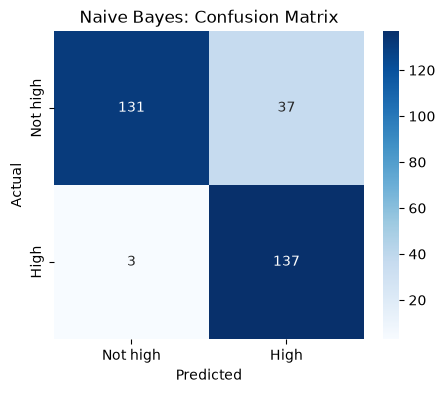

In [3]:
y_pred = nb.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, target_names=["Not high", "High"]))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not high", "High"], yticklabels=["Not high", "High"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Naive Bayes: Confusion Matrix")
plt.show()

**How to read these metrics**

- **Accuracy**: share of all test plots classified correctly.
- **Precision (High)**: of the plots predicted "high", how many really are high.
- **Recall (High)**: of the truly high plots, how many the model caught.
- **F1**: the balance of precision and recall.
- **Confusion matrix**: rows are the true class, columns the predicted class. The
  diagonal holds correct predictions; the off-diagonal cells are the two kinds of mistake.

## Testing the Independence Assumption

`rainfall_mm_avg` and `groundwater_stress_pct` each take a single value per district,
so they carry largely the same information. Naive Bayes multiplies their likelihoods
as if they were independent evidence, so it counts the district twice. Below, the
correlations are shown, and the model is re-run without groundwater to see the effect.

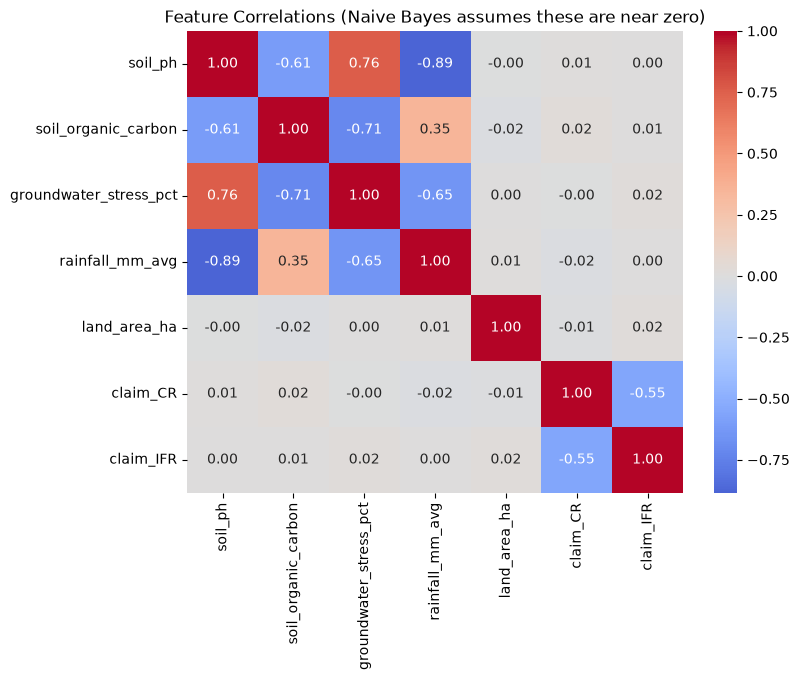

CV accuracy, all features:         0.8807
CV accuracy, without groundwater:  0.8766


In [4]:
plt.figure(figsize=(8, 6))
sns.heatmap(X_train.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature Correlations (Naive Bayes assumes these are near zero)")
plt.show()

all_feats = cross_val_score(GaussianNB(), X_train, y_train, cv=cv).mean()
no_gw = cross_val_score(GaussianNB(), X_train.drop(columns="groundwater_stress_pct"), y_train, cv=cv).mean()
print(f"CV accuracy, all features:         {all_feats:.4f}")
print(f"CV accuracy, without groundwater:  {no_gw:.4f}")

## Comparison with Logistic Regression and Probability Calibration

Naive Bayes is compared with Logistic Regression (Lab 9) using 5-fold CV. Because of
the independence assumption, Naive Bayes also tends to produce **over-confident**
probabilities (close to 0 or 1), which the histogram shows.

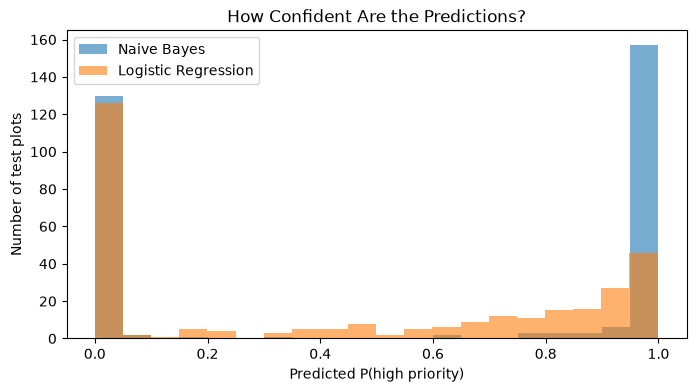

,Model,CV accuracy,Test accuracy
0,Gaussian Naive Bayes,0.8807,0.8701
1,Logistic Regression,0.8961,0.8994


In [5]:
from sklearn.linear_model import LogisticRegression

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
comparison = pd.DataFrame({
    "Model": ["Gaussian Naive Bayes", "Logistic Regression"],
    "CV accuracy": [cross_val_score(GaussianNB(), X_train, y_train, cv=cv).mean().round(4),
                    cross_val_score(logreg, X_train, y_train, cv=cv).mean().round(4)],
    "Test accuracy": [round(nb.score(X_test, y_test), 4),
                      round(logreg.fit(X_train, y_train).score(X_test, y_test), 4)],
})

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(nb.predict_proba(X_test)[:, 1], bins=20, alpha=0.6, label="Naive Bayes")
ax.hist(logreg.predict_proba(X_test)[:, 1], bins=20, alpha=0.6, label="Logistic Regression")
ax.set_xlabel("Predicted P(high priority)")
ax.set_ylabel("Number of test plots")
ax.set_title("How Confident Are the Predictions?")
ax.legend()
plt.show()

comparison

## Conclusion

Gaussian Naive Bayes was used to classify plots as high or not-high PMKSY priority.

| Model | CV accuracy | Test accuracy |
|---|---|---|
| Gaussian Naive Bayes | 0.881 | 0.870 |
| Logistic Regression | 0.896 | 0.899 |

**Observations**

1. **What it learned:** high-priority plots have much lower average rainfall (996 mm vs
   1,529 mm) and much higher groundwater stress (56.9% vs 37.7%), with slightly smaller
   land areas. These are exactly the features the PMKSY rule rewards.
2. **Errors:** Naive Bayes has a very high recall for "High" (0.98) but lower precision
   (0.79): it labels too many plots as high priority.
3. **Independence assumption:** several features are strongly correlated (for example
   rainfall with groundwater stress, and rainfall with soil pH), because all of them
   change together from district to district. Naive Bayes treats each one as
   independent evidence, so the same district information is counted several times
   and its probabilities become over-confident: 93% of its test-set probabilities are
   below 0.05 or above 0.95, against 56% for Logistic Regression. Removing groundwater alone did not help (0.881 to 0.877), because the
   remaining features still overlap.
4. **Comparison:** Logistic Regression, which makes no independence assumption, is
   about 2-3 percentage points more accurate. Naive Bayes is still a reasonable,
   very fast baseline that needs no scaling or tuning.
